In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

import sqlite3

## Create SQLite3 db and merge CSVs

In [13]:
#read in previously transformed CSVs (from prev milestones)
games_details = pd.read_csv("games_details.csv")
contracts = pd.read_csv("contracts.csv")
player_stats = pd.read_csv("player_stats.csv")

#create sqlite db
conn = sqlite3.connect("dsc540_project")

In [14]:
#func to check for successful connection
def is_opened(conn):
    try:
        conn.execute("SELECT * FROM contracts LIMIT 1")
        return True
    except sqlite3.ProgrammingError as e:
        print(f"Connection closed {e}")
        return False
        
print(is_opened(conn))

True


In [15]:
#load CSVs to SQLite3 db
games_details.to_sql("games_details", conn, if_exists = "replace", index = False)  #flat file
contracts.to_sql("contracts", conn, if_exists = "replace", index = False)          #html table
player_stats.to_sql("player_stats", conn, if_exists = "replace", index = False)    #api

1585

In [16]:
#join selected cols from 3 CSVs into merged dataset with SQLite3
query = """
SELECT 
    g.PLAYER_NAME,
    g.PLUS_MINUS,
    g.Team_Name_Key,
    c."2025-26",
    c."2026-27",
    c."2027-28",
    c."2028-29",
    c."2029-30",
    c."2030-31",
    c.Guaranteed,
    c.Total_Contract_Value,
    c."Guaranteed_%",
    p.GP,
    p.W,
    p.L, 
    p.W_PCT,
    p.Mins_Played,
    p.PTS,
    p.GP_RANK,
    p.W_RANK,
    p.L_RANK,
    p.W_PCT_RANK,
    p.MIN_RANK,
    p.FGM_RANK,
    p.FGA_RANK,
    p.FG_PCT_RANK,
    p.FG3M_RANK,
    p.FG3A_RANK,
    p.FG3_PCT_RANK,
    p.FTM_RANK,
    p.FTA_RANK,
    p.FT_PCT_RANK,
    p.OREB_RANK,
    p.DREB_RANK,
    p.REB_RANK,
    p.AST_RANK,
    p.TOV_RANK,
    p.STL_RANK,
    p.BLK_RANK,
    p.BLKA_RANK,
    p.PF_RANK,
    p.PFD_RANK,
    p.PTS_RANK,
    p.PLUS_MINUS_RANK

FROM games_details AS g
JOIN contracts AS c
    ON g.Player_Key = c.Player_Key
JOIN player_stats AS p
    ON g.Player_Key = p.Player_Key
"""

#create df for merged data
merged_df = pd.read_sql_query(query, conn)

#close db connection
conn.close()

merged_df.head()

,PLAYER_NAME,PLUS_MINUS,Team_Name_Key,2025-26,2026-27,2027-28,2028-29,2029-30,2030-31,Guaranteed,...,REB_RANK,AST_RANK,TOV_RANK,STL_RANK,BLK_RANK,BLKA_RANK,PF_RANK,PFD_RANK,PTS_RANK,PLUS_MINUS_RANK
0,Jeremy Sochan,-14.0,San Antonio Spurs,7096231.0,0.0,0.0,0.0,0.0,0.0,7096231.0,...,99,242,181,244,219,1501,1453,219,217,1368
1,Jakob Poeltl,-4.0,San Antonio Spurs,19500000.0,19500000.0,0.0,0.0,0.0,0.0,39000000.0,...,25,174,98,103,36,1432,1546,149,123,1159
2,Devin Vassell,-18.0,San Antonio Spurs,27000000.0,27000000.0,24652174.0,27000000.0,0.0,0.0,105652174.0,...,202,134,162,41,166,1371,1368,245,80,1549
3,Zach Collins,-13.0,San Antonio Spurs,18080496.0,0.0,0.0,0.0,0.0,0.0,18080496.0,...,163,299,325,467,201,1172,1455,296,406,1108
4,Malaki Branham,-6.0,San Antonio Spurs,4962033.0,0.0,0.0,0.0,0.0,0.0,4962033.0,...,1356,1136,1191,1440,1346,352,282,1236,1142,605


# Visualization 1: Histogram of Contract Salaries for the upcoming 2025-26 NBA Season

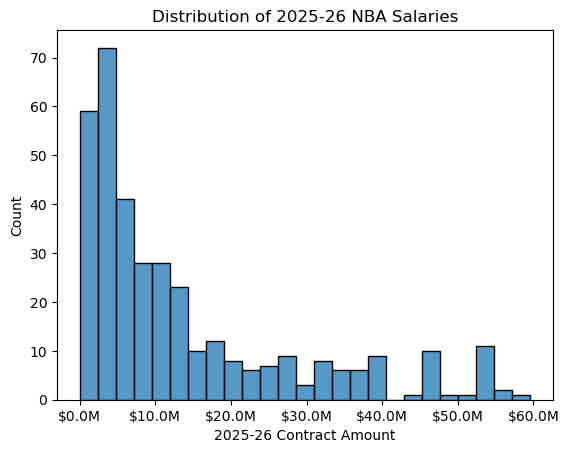

In [17]:
#create hist of contract amount distributions for the upcoming NBA season from the contracts HTML data
sns.histplot(contracts["2025-26"], bins = 25)
plt.title("Distribution of 2025-26 NBA Salaries")
plt.xlabel("2025-26 Contract Amount")

#lamda func to help clean up the x-axis ticks
plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.show()

There are 450 NBA players with contracts for the upcoming season.  This visualization gives us an idea of what the distribution of NBA player salaries look like for the 25-26 season.  We see a right-skewed distribution as most players make less than \$20M.

# Visualization 2: Bar Chart of Top 10 NBA Players in Points Scored from the most recent season 

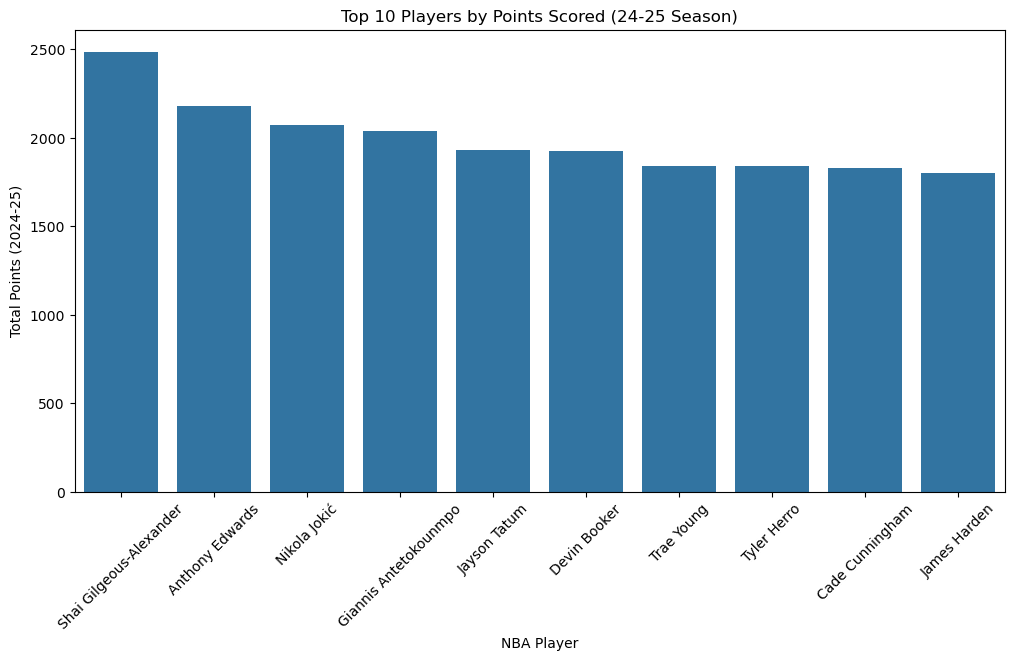

In [18]:
#create a list of the Top 10 players in scoring from the API data
top_players = player_stats.sort_values("PTS", ascending = False).head(10)

#create bar chart displaying the top 10 scorers from the most recent NBA season
plt.figure(figsize = (12, 6))  #adjust size for readability
sns.barplot(data = top_players, x = "PLAYER_NAME", y = "PTS")

plt.title("Top 10 Players by Points Scored (24-25 Season)")
plt.ylabel("Total Points (2024-25)")
plt.xlabel("NBA Player")
plt.xticks(rotation = 45)  #rotate names for readability
plt.show()

This visualization shows us who are the top 10 point scorers from the previous NBA season.  The Top 10 contracts for the upcoming NBA season are:  
1. Stephen Curry
2. Joel Embiid
3. Nikola Jokic
4. Kevin Durant
5. Jayson Tatum
6. Giannis Antetokounmpo
7. Anthony Davis
8. Jimmy Butler
9. Damian Lillard
10. Bradley Beal

# Visualization 3: Scatter Plot of Salary vs Points Rank

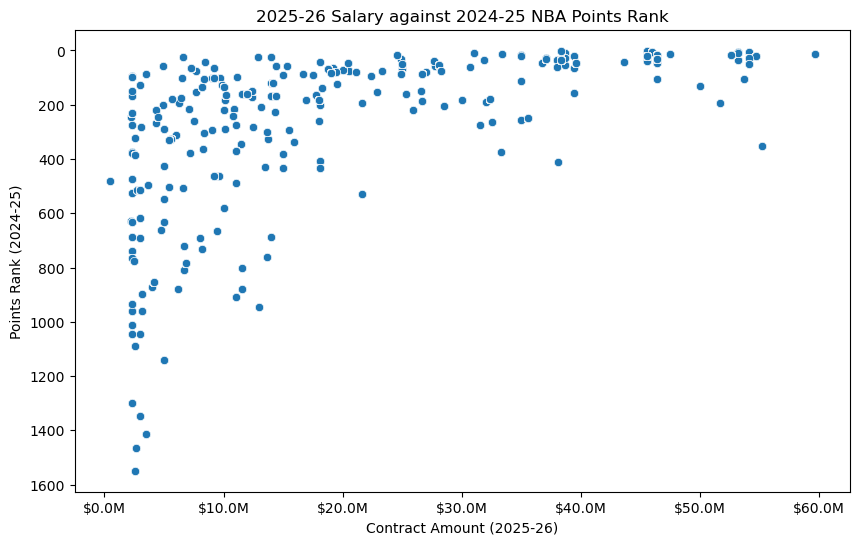

In [8]:
#create scatter plot from joined data of contracts and player_stats 
plt.figure(figsize = (10, 6))
sns.scatterplot(data = merged_df, x = "2025-26", y = "PTS_RANK")

plt.title("2025-26 Salary against 2024-25 NBA Points Rank")
plt.xlabel("Contract Amount (2025-26)")
plt.ylabel("Points Rank (2024-25)")

#lamda func to help clean up the x-axis ticks
plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

#invert PTS_RANK axis so rank 1 is at the top
plt.gca().invert_yaxis()
plt.show()

This scatterplot shows us that higher contract amounts (greater than $20M) have a correlation with higher point rankings.  

# Visualization 4: Line plot of Average Salary by Win Rank

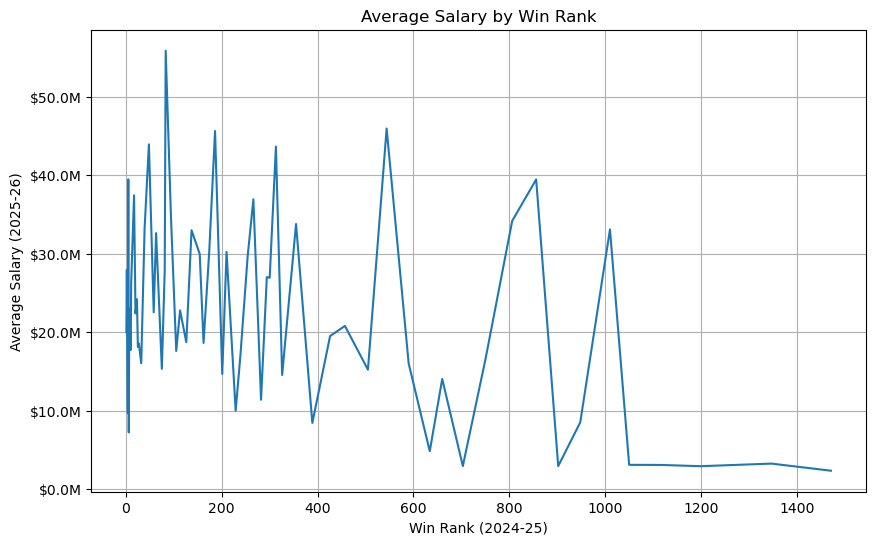

In [19]:
#aggregate average salary per win rank from player_stats data
avg_salary_by_rank = merged_df.groupby("W_RANK")["2025-26"].mean().reset_index()

#sort by win rank
avg_salary_by_rank = avg_salary_by_rank.sort_values("W_RANK")

#plot data from player_stats and contracts joined data
plt.figure(figsize = (10,6))
sns.lineplot(data = avg_salary_by_rank, x = "W_RANK", y = "2025-26") 

plt.title("Average Salary by Win Rank")
plt.xlabel("Win Rank (2024-25)")
plt.ylabel("Average Salary (2025-26)")
plt.grid()

#lamda func to help clean up the y-axis ticks
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x*1e-6:.1f}M"))
plt.show()

Aggregated the salaries per rank to see the trend in salaries across Win Rank.  This visualizations shows us that average salaries are in a smaller range for top players in Win Rank, when compared ranks higher than 400.  We also see a more chaotic peaks and valleys past the 400 rank.  Win Rank does not seem to align as well as Points Rank and salaries.

# Visualization 5: Box Plot of Salary Distribution by NBA Teams

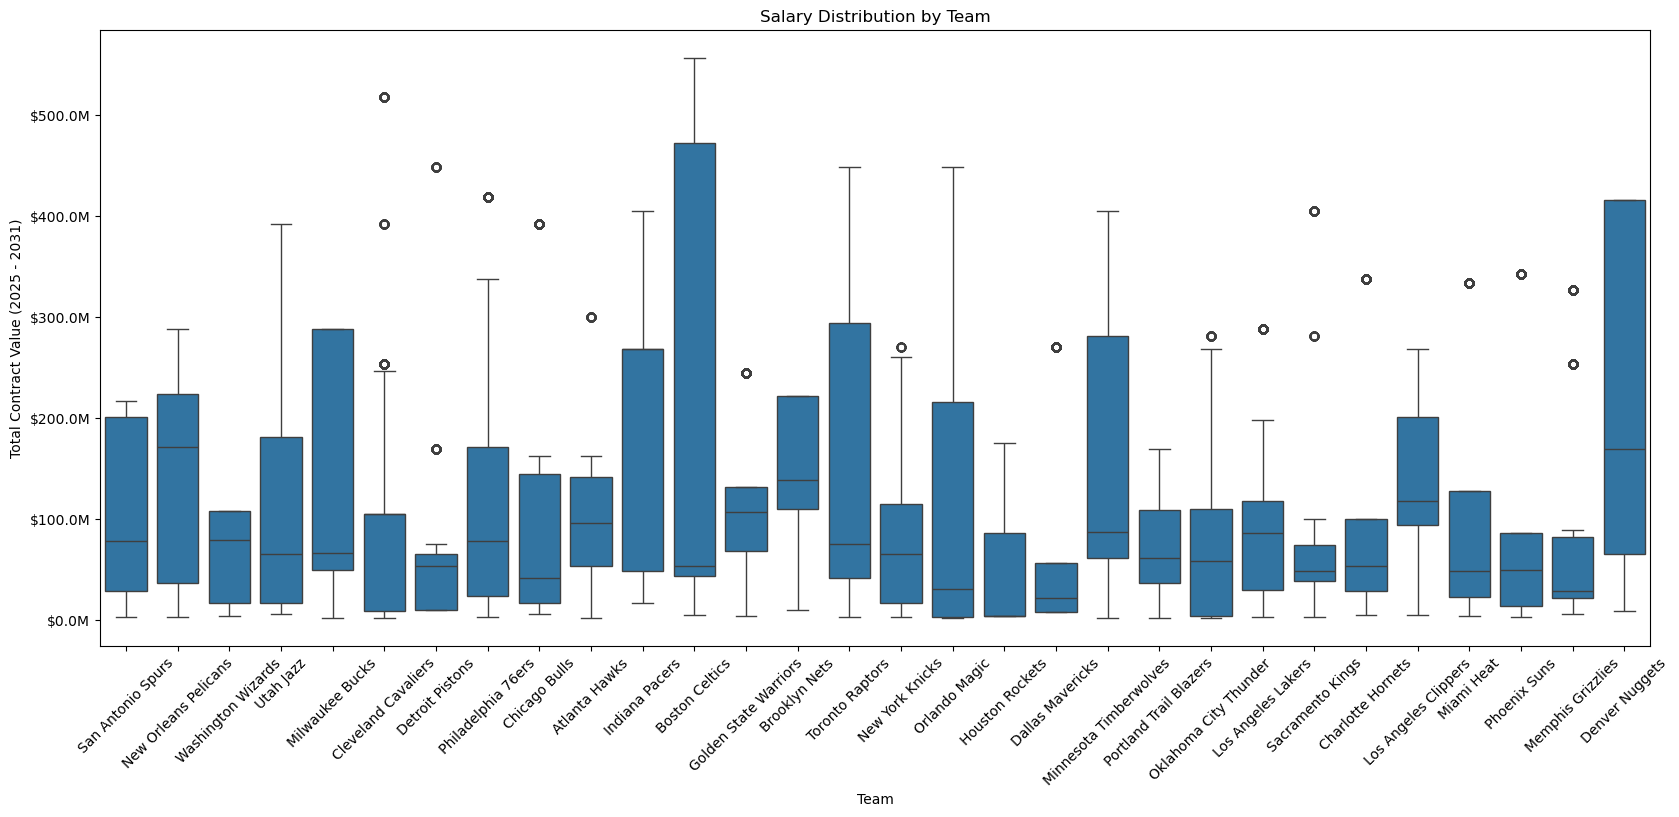

In [20]:
#create box plot of total contract amounts by nba team from contracts and games_details data
plt.figure(figsize = (20,8))
sns.boxplot(data = merged_df, x = "Team_Name_Key", y = "Total_Contract_Value")

plt.title("Salary Distribution by Team")
plt.xlabel("Team")
plt.ylabel("Total Contract Value (2025 - 2031)")
plt.xticks(rotation = 45) #rotate for readability

#lambda func to help clean up the y-axis ticks
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x*1e-6:.1f}M"))
plt.show()

This visualization gives us an idea on how much teams are spending on their individual player contracts through the 2031 NBA season.  

# Visualization 6: Top 10 Teams by Salary and Win Rank

/var/folders/dj/tlflpdsx4cjcpzn7v8wdcddc0000gn/T/ipykernel_47622/1148384699.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation = 45)


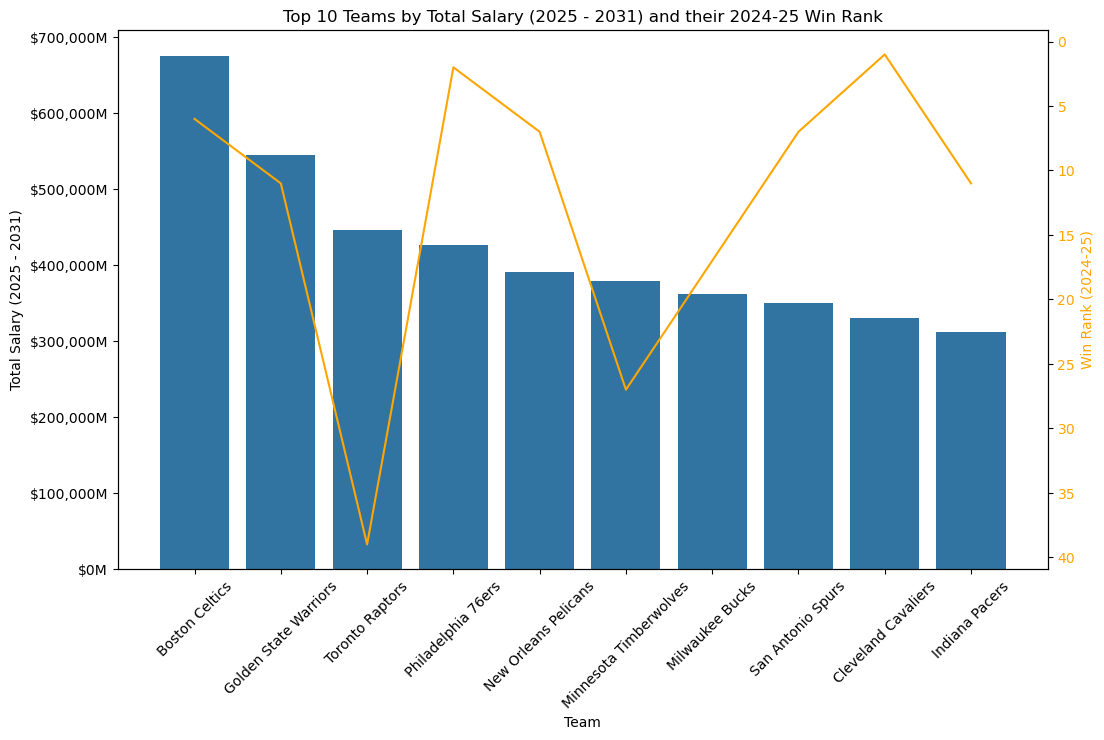

In [21]:
#sum salary across seasons for each team from contracts data
team_summary = merged_df.groupby("Team_Name_Key").agg({
    "Total_Contract_Value": "sum",
    "W_RANK": "min"  #use min rank per team instead of mean
}).reset_index()

#retrieve top 10 teams by Total_Salary
top_10_teams = team_summary.nlargest(10, "Total_Contract_Value")

#plot
fig, ax1 = plt.subplots(figsize = (12,7))

#bar plot for total salary
sns.barplot(data = top_10_teams, x = "Team_Name_Key", y = "Total_Contract_Value", ax = ax1)
ax1.set_ylabel("Total Salary (2025 - 2031)")
ax1.set_xlabel("Team")
ax1.tick_params(axis = "y")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation = 45)

#format y-axis labels in millions
def millions_formatter(x, pos):
    return f"${x*1e-6:,.0f}M"
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(millions_formatter))

#create a second y-axis to plot Win rank
ax2 = ax1.twinx()
sns.lineplot(data = top_10_teams, x = "Team_Name_Key", y = "W_RANK", color = "orange", ax = ax2)
ax2.set_ylabel("Win Rank (2024-25)", color = "orange")
ax2.invert_yaxis()  #this will ensure rank 1 is at top for readability
ax2.tick_params(axis = "y", labelcolor = "orange")

plt.title("Top 10 Teams by Total Salary (2025 - 2031) and their 2024-25 Win Rank")
plt.show()

Following up on the previous Visualization 5, this gives us a view of the top 10 NBA teams by Total Salary (2025 - 2031) and their Win Rank from the most recent season.  Not all teams are paying the same amount for success... and failures.

I got out of my comfort zone for this visualization.  Did research on how to create a view like this and combine data.

# Final dataset

In [22]:
merged_df

,PLAYER_NAME,PLUS_MINUS,Team_Name_Key,2025-26,2026-27,2027-28,2028-29,2029-30,2030-31,Guaranteed,...,REB_RANK,AST_RANK,TOV_RANK,STL_RANK,BLK_RANK,BLKA_RANK,PF_RANK,PFD_RANK,PTS_RANK,PLUS_MINUS_RANK
0,Jeremy Sochan,-14.0,San Antonio Spurs,7096231.0,0.0,0.0,0.0,0.0,0.0,7096231.0,...,99,242,181,244,219,1501,1453,219,217,1368
1,Jakob Poeltl,-4.0,San Antonio Spurs,19500000.0,19500000.0,0.0,0.0,0.0,0.0,39000000.0,...,25,174,98,103,36,1432,1546,149,123,1159
2,Devin Vassell,-18.0,San Antonio Spurs,27000000.0,27000000.0,24652174.0,27000000.0,0.0,0.0,105652174.0,...,202,134,162,41,166,1371,1368,245,80,1549
3,Zach Collins,-13.0,San Antonio Spurs,18080496.0,0.0,0.0,0.0,0.0,0.0,18080496.0,...,163,299,325,467,201,1172,1455,296,406,1108
4,Malaki Branham,-6.0,San Antonio Spurs,4962033.0,0.0,0.0,0.0,0.0,0.0,4962033.0,...,1356,1136,1191,1440,1346,352,282,1236,1142,605
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72726,Bradley Beal,NaN,Washington Wizards,53666270.0,0.0,0.0,0.0,0.0,0.0,53666270.0,...,347,122,131,146,209,1223,1463,184,105,1550
72727,LeBron James,NaN,Miami Heat,52627153.0,0.0,0.0,0.0,0.0,0.0,52627153.0,...,26,7,4,82,118,1524,1321,30,15,1248
72728,Anthony Davis,NaN,None,54126450.0,58456566.0,62786682.0,0.0,0.0,0.0,112583016.0,...,20,135,94,140,10,1464,1317,27,51,430
72729,Harrison Barnes,NaN,Golden State Warriors,19000000.0,0.0,0.0,0.0,0.0,0.0,19000000.0,...,138,215,422,306,440,1354,1194,111,84,1078


# Summary

This project started off as a curious interest in how NBA player contracts compare against player performance.  As I grew more familiar with the datasets, I realized I can also see views on impacts to the overall teams.  It's interesting to see how more questions pop up during the data gathering and cleaning.  In addition, other learnings included to not assume all data is setup for straightforward, simple data cleaning.  Time must be spent to understand the data columns and rows to ensure there are no gaps or breaks in the tables; I experienced a few unique lines/rows in the HTML and API data.  Lastly, I learned how vast the Python community is.  While researching APIs, I discovered that the two options I was considering had their Python libraries built to make API calling simpler.  This was my first time seeing a third party creating a library like that in Python.

Regarding the ethical implications of this project, the three original data sources were merged into a dataset containing a total of 44 columns (3 from flat file, 9 from HTML, and 32 from API).  Terms of Use from the original datasets have not changed and activities performed continue to meet those terms.  No personally identifiable information is found in the merged dataset.  There were no additional changes made to the data once merged.  As for risks, most transformations were to create clarity around the data and included relative documentation.  There should be no concerns of any risks.  The primary assumption for the primary key is that all player names are unique and consistent and that there is associated data for each player.  The overall, subsequent assumption is that the player names in each table match perfectly after transformation without mismatches or missing values.  Sourcing for the original datasets came from reliable sources: Kaggle is often sourced from publicly available or officially compiled NBA statistics.  Basketball-reference.com is widely regarded as one of the most comprehensive and trusted sports stats sites.  Their data is collected from official NBA repots, box scores, and league stats.  The nba_api data is a popular Python library that interfaces with the official NBA stats endpoints or public data sources.  All data was acquired in an ethical way: from publicly available data, no private or sensitive data collected, aligned with Terms of Use, and is not for commercial use.  Mitigation efforts should include documentation of processes and sources to share alignment with Terms of Use, privacy, and overall transparency.